In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm # add1

In [2]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # 상수항(intercept) 추가를 위함

In [3]:
df_total = pd.read_csv('nba20232024_total.txt', delimiter = ',')
df_advanced = pd.read_csv('nba20232024_advanced.txt', delimiter = ',')

In [4]:
Merged_df = pd.merge(df_total, df_advanced, on = 'Player')
Merged_df['FGF'] = Merged_df['FGA'] - Merged_df['FG']  ### FGF(야투 실패 개수) 변수 추가
len(Merged_df.columns)

63

In [5]:
columns_need = ['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'FT%', 'TOV', 'FGF', 'PF', 'PER', 'Pos_x']

In [6]:
Merged_df = Merged_df[columns_need]
Merged_df.head()

,Player,G_x,PTS,TRB,AST,STL,BLK,FT%,TOV,FGF,PF,PER,Pos_x
0,Luka Dončić,70,2370,647,686,99,38,0.786,282,848,149,28.1,PG
1,Shai Gilgeous-Alexander,75,2254,415,465,150,67,0.874,162,691,184,29.3,PG
2,Giannis Antetokounmpo,73,2222,841,476,87,79,0.657,250,532,210,29.9,PF
3,Jalen Brunson,77,2212,278,519,70,13,0.847,186,858,144,23.4,PG
4,Nikola Jokić,79,2085,976,708,108,68,0.817,237,589,194,31.0,C


In [7]:
# 결측치(NaN), 0 있는 행렬 정리
Merged_df = Merged_df.dropna()
Merged_df = Merged_df[Merged_df['G_x'] != 0]

In [8]:
columns_original_need = ['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%', 'TOV_g', 'FGF_g', 'PF_g', "Pos_x"]

In [9]:
# nba_data_df: Standard DataFrame for regression
nba_data_df = pd.DataFrame(columns = columns_original_need)
nba_data_df.columns

Index(['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%',
       'TOV_g', 'FGF_g', 'PF_g', 'Pos_x'],
      dtype='object')

In [10]:
nba_data_df['Player'] = Merged_df['Player']
nba_data_df['PER'] = Merged_df['PER']
nba_data_df['Pos_x'] = Merged_df['Pos_x']
nba_data_df['PTS_g'] = Merged_df['PTS'] / Merged_df['G_x']
nba_data_df['TRB_g'] = Merged_df['TRB'] / Merged_df['G_x']
nba_data_df['AST_g'] = Merged_df['AST'] / Merged_df['G_x']
nba_data_df['STL_g'] = Merged_df['STL'] / Merged_df['G_x']
nba_data_df['BLK_g'] = Merged_df['BLK'] / Merged_df['G_x']
nba_data_df['FT%'] = Merged_df['FT%']
nba_data_df['TOV_g'] = Merged_df['TOV'] / Merged_df['G_x']
nba_data_df['FGF_g'] = Merged_df['FGF'] / Merged_df['G_x']
nba_data_df['PF_g'] = Merged_df['PF'] / Merged_df['G_x']

In [11]:
nba_data_df.head()

,Player,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,FGF_g,PF_g,Pos_x
0,Luka Dončić,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,12.114286,2.128571,PG
1,Shai Gilgeous-Alexander,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,9.213333,2.453333,PG
2,Giannis Antetokounmpo,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,7.287671,2.876712,PF
3,Jalen Brunson,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,11.142857,1.870130,PG
4,Nikola Jokić,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,7.455696,2.455696,C


In [12]:
# 원본데이터의 기술적 통계량
nba_data_df_describe = nba_data_df.drop(columns = ['FGF_g'])
nba_data_df_describe = nba_data_df_describe.head(300)
nba_data_df_describe.describe()

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,15.048000,12.867313,4.657728,2.975382,0.804123,0.543300,0.779633,1.444288,1.963161
std,4.328481,6.374328,2.387919,1.990023,0.333661,0.462125,0.084507,0.783291,0.585321
min,7.700000,4.238806,0.833333,0.460000,0.190476,0.031250,0.440000,0.287879,0.727273
25%,11.900000,7.776364,3.034685,1.380373,0.557494,0.252799,0.731500,0.856673,1.500000
50%,14.400000,11.013932,4.075000,2.372088,0.775986,0.446581,0.791500,1.271058,1.928017
75%,17.625000,16.730640,5.529004,4.135704,0.985861,0.663731,0.836250,1.800893,2.344705
max,34.100000,34.692308,13.658537,10.898551,2.050000,3.577465,0.944000,4.351852,3.590909


In [13]:
#For Checking VIF
nba_data_df_1 = nba_data_df.drop(columns = ['Player','Pos_x'])
nba_data_df_2 = nba_data_df.drop(columns = ['Player', 'FGF_g','Pos_x']) # PTS_g, FGF_g 둘 사이 VIF가 너무 높아서 덜 중요한 FGF_g 죽이기

## Test Regression

In [14]:
nba_data_regression_test_df = nba_data_df_2.copy()

In [15]:
nba_data_regression_test_df.head(5)

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
0,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,2.128571
1,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,2.453333
2,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,2.876712
3,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,1.870130
4,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,2.455696


In [16]:
nba_data_regression_test_df = nba_data_regression_test_df.head(300)
nba_data_regression_test_df.describe()

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,15.048000,12.867313,4.657728,2.975382,0.804123,0.543300,0.779633,1.444288,1.963161
std,4.328481,6.374328,2.387919,1.990023,0.333661,0.462125,0.084507,0.783291,0.585321
min,7.700000,4.238806,0.833333,0.460000,0.190476,0.031250,0.440000,0.287879,0.727273
25%,11.900000,7.776364,3.034685,1.380373,0.557494,0.252799,0.731500,0.856673,1.500000
50%,14.400000,11.013932,4.075000,2.372088,0.775986,0.446581,0.791500,1.271058,1.928017
75%,17.625000,16.730640,5.529004,4.135704,0.985861,0.663731,0.836250,1.800893,2.344705
max,34.100000,34.692308,13.658537,10.898551,2.050000,3.577465,0.944000,4.351852,3.590909


In [17]:
nba_data_regression_test_df.head(5)

,PER,PTS_g,TRB_g,AST_g,STL_g,BLK_g,FT%,TOV_g,PF_g
0,28.1,33.857143,9.242857,9.800000,1.414286,0.542857,0.786,4.028571,2.128571
1,29.3,30.053333,5.533333,6.200000,2.000000,0.893333,0.874,2.160000,2.453333
2,29.9,30.438356,11.520548,6.520548,1.191781,1.082192,0.657,3.424658,2.876712
3,23.4,28.727273,3.610390,6.740260,0.909091,0.168831,0.847,2.415584,1.870130
4,31.0,26.392405,12.354430,8.962025,1.367089,0.860759,0.817,3.000000,2.455696


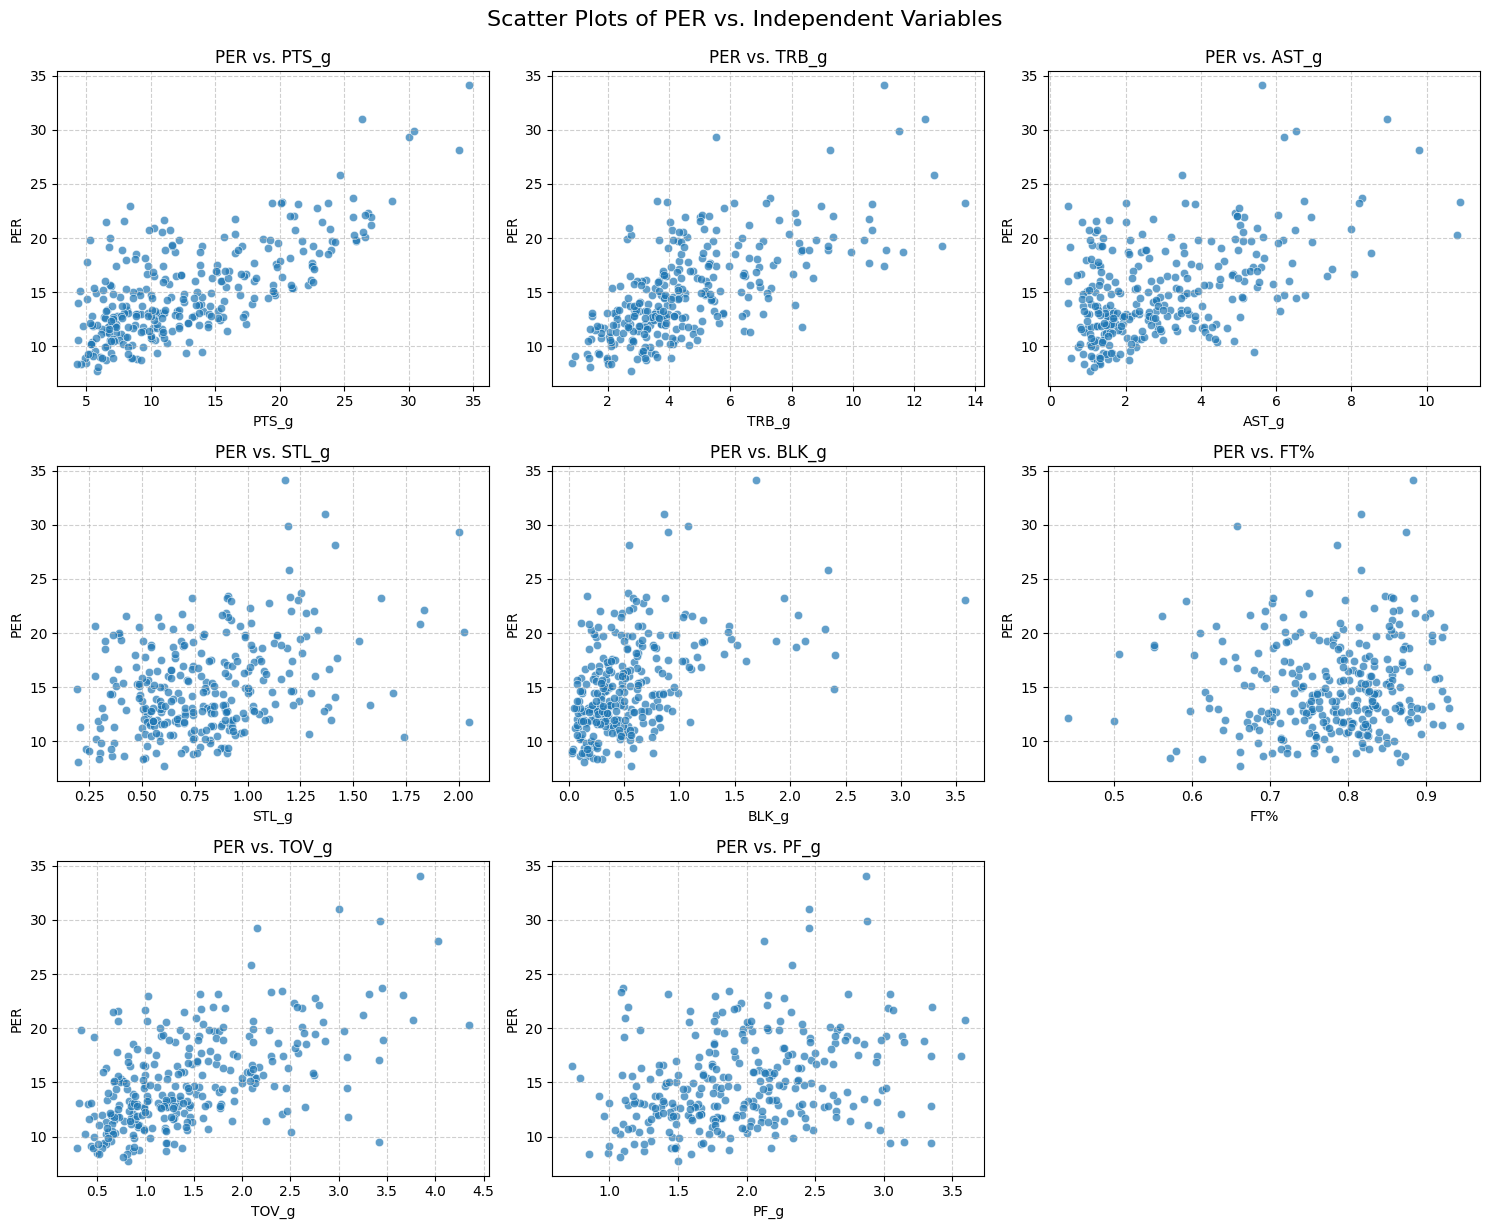

In [18]:

# list of independent variables for scatter figure.
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'STL_g', 'BLK_g', 'FT%','TOV_g', 'PF_g']
dependent_variable = 'PER'

# setting
n_cols = 3
n_rows = (len(independent_variables) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4)) 

for i, col in enumerate(independent_variables):
    plt.subplot(n_rows, n_cols, i + 1) 
    sns.scatterplot(x=col, y=dependent_variable, data=nba_data_regression_test_df, alpha=0.7)
    plt.title(f'{dependent_variable} vs. {col}')
    plt.xlabel(col)
    plt.ylabel(dependent_variable)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout() 
plt.suptitle(f'Scatter Plots of {dependent_variable} vs. Independent Variables', y=1.02, fontsize=16) # 전체 제목
plt.show()



In [19]:
nba_data_regression_test_df = nba_data_regression_test_df.head(300)
y_linear1 = nba_data_regression_test_df['PER']
X_linear1 = nba_data_regression_test_df.drop(columns = ['PER'])
X_linear1 = sm.add_constant(X_linear1)

model_linear1 = sm.OLS(y_linear1, X_linear1)
results_linear1 = model_linear1.fit()
print(results_linear1.summary())

                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.726
Model:                            OLS   Adj. R-squared:                  0.718
Method:                 Least Squares   F-statistic:                     96.39
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           3.17e-77
Time:                        14:30:07   Log-Likelihood:                -670.54
No. Observations:                 300   AIC:                             1359.
Df Residuals:                     291   BIC:                             1392.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.4639      1.559      6.072      0.0

In [20]:
# OLS Regression Results
## nba_data_regression_test_df_head_300 => exclude STl, FT% variables for not significant t-value and coefficient.
nba_data_regression_test_df_head_300 = nba_data_regression_test_df.head(300)
nba_data_regression_test_df_head_300 = nba_data_regression_test_df_head_300.drop(columns = ['STL_g', 'FT%'])
y_linear2 = nba_data_regression_test_df_head_300['PER']
X_linear2 = nba_data_regression_test_df_head_300.drop(columns = ['PER'])
X_linear2 = sm.add_constant(X_linear2)

model_linear2 = sm.OLS(y_linear2, X_linear2)
results_linear2 = model_linear2.fit()
print("------ 회귀 분석 결과 요약------")
print(results_linear2.summary())

------ 회귀 분석 결과 요약------
                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.724
Model:                            OLS   Adj. R-squared:                  0.719
Method:                 Least Squares   F-statistic:                     128.4
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           5.53e-79
Time:                        14:30:07   Log-Likelihood:                -671.38
No. Observations:                 300   AIC:                             1357.
Df Residuals:                     293   BIC:                             1383.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.6066      

## Regression Variable's Distribution

In [21]:
columns_to_plot = ['PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

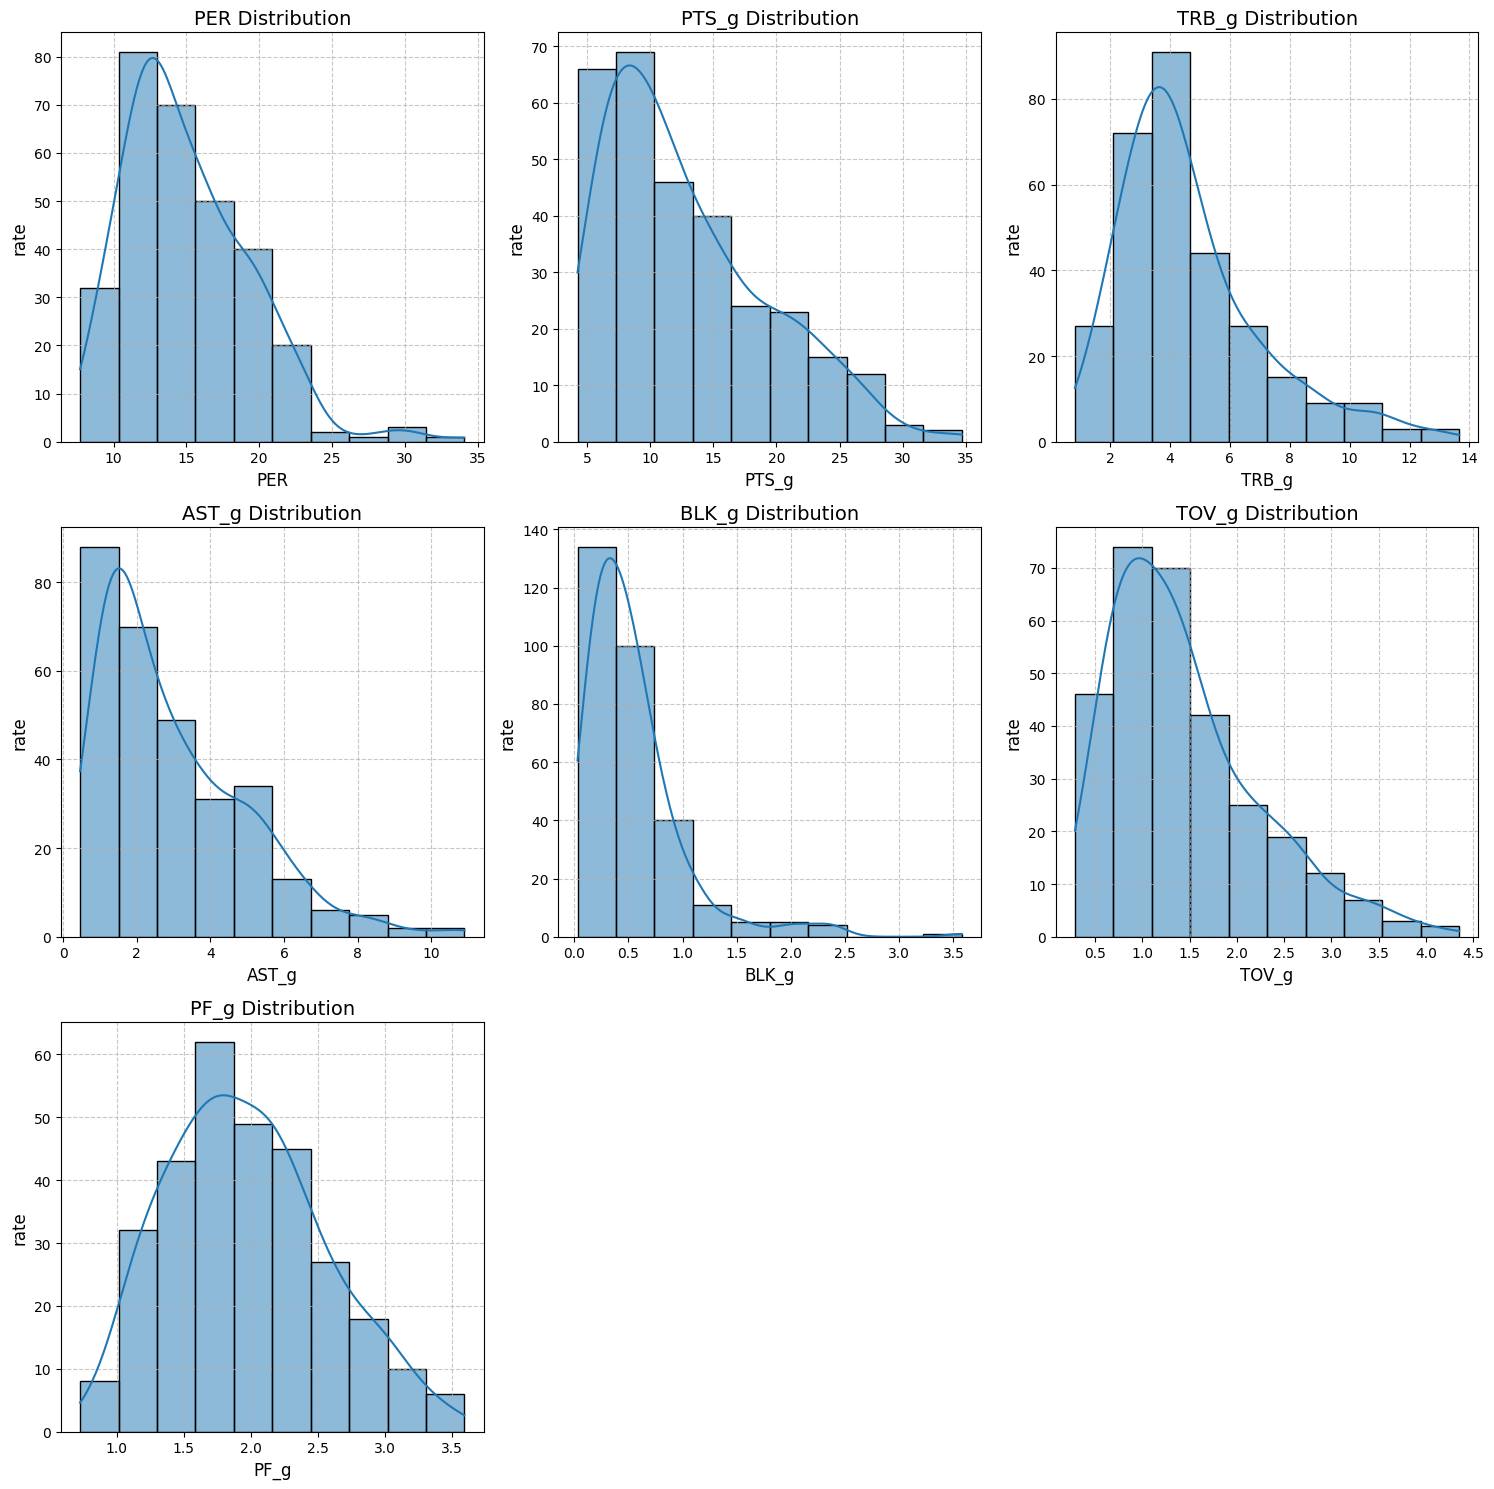

In [22]:
num_cols = len(columns_to_plot)
num_rows = (num_cols + 2) // 3 
plt.figure(figsize=(15, 5 * num_rows))

for i, col in enumerate(columns_to_plot):
    plt.subplot(num_rows, 3, i + 1) 
    sns.histplot(nba_data_regression_test_df_head_300[col], kde=True, bins=10) 
    plt.title(f'{col} Distribution', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('rate', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout() 
plt.show()

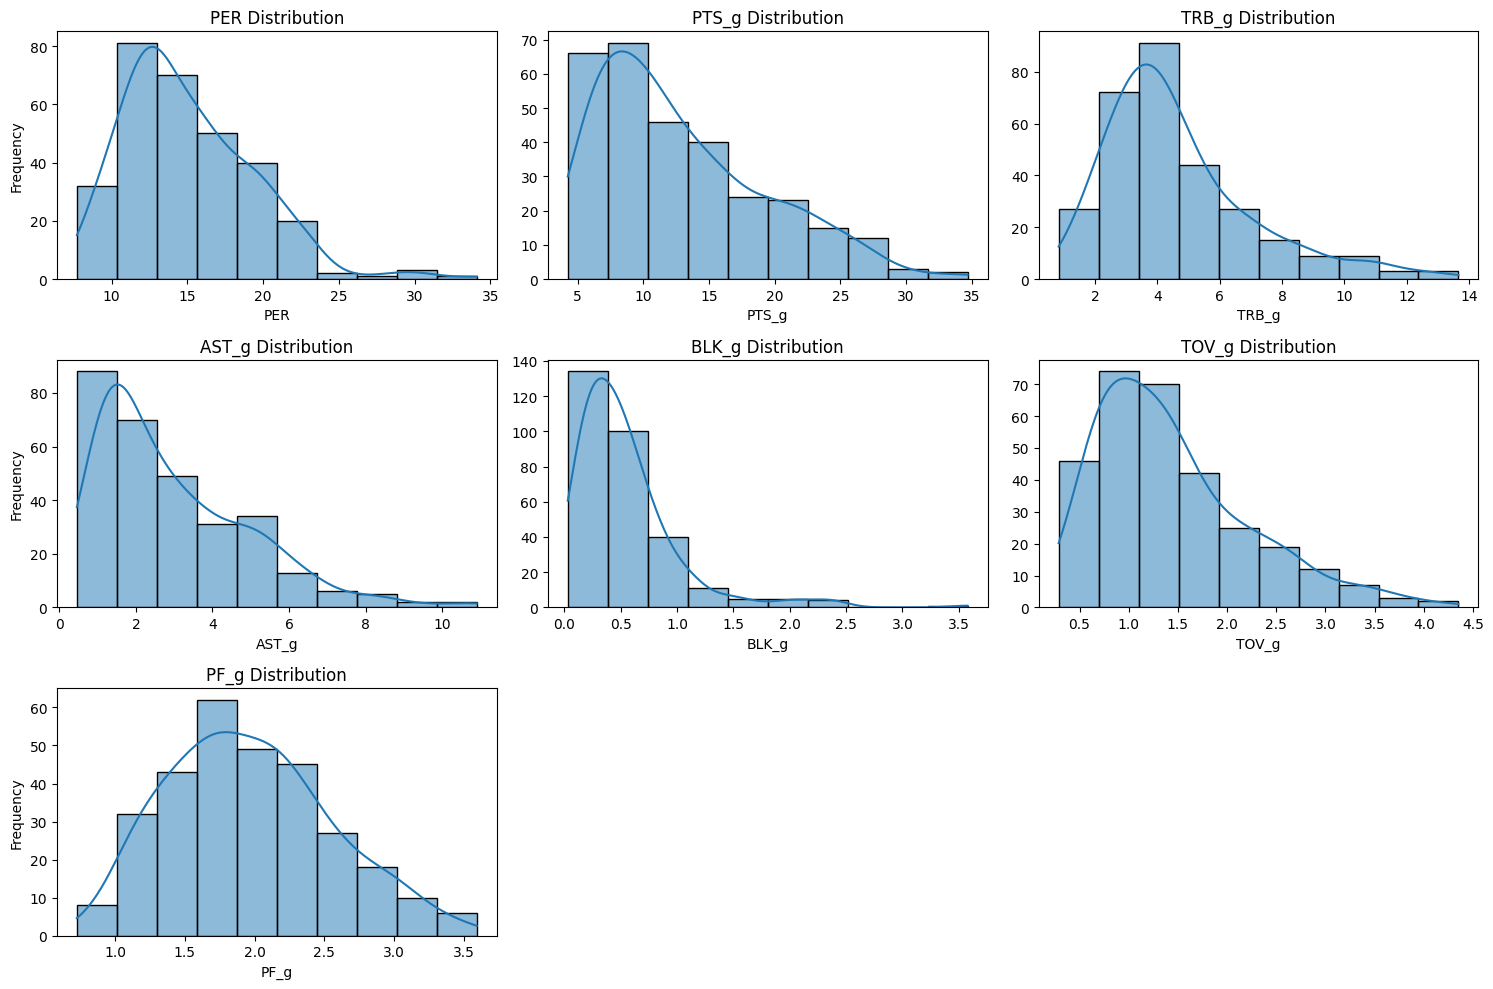

In [23]:
df_head_300 = nba_data_regression_test_df_head_300.copy()

columns_to_plot = ['PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

plt.figure(figsize=(15, 10)) 

for i, col in enumerate(columns_to_plot):
    plt.subplot(3, 3, i + 1) 
    sns.histplot(df_head_300[col], kde=True, bins=10) 
    plt.title(f'{col} Distribution') 
    plt.xlabel(col) 
    plt.ylabel('Frequency' if i % 3 == 0 else '') 

plt.tight_layout() 
plt.show()

## Log Transformation

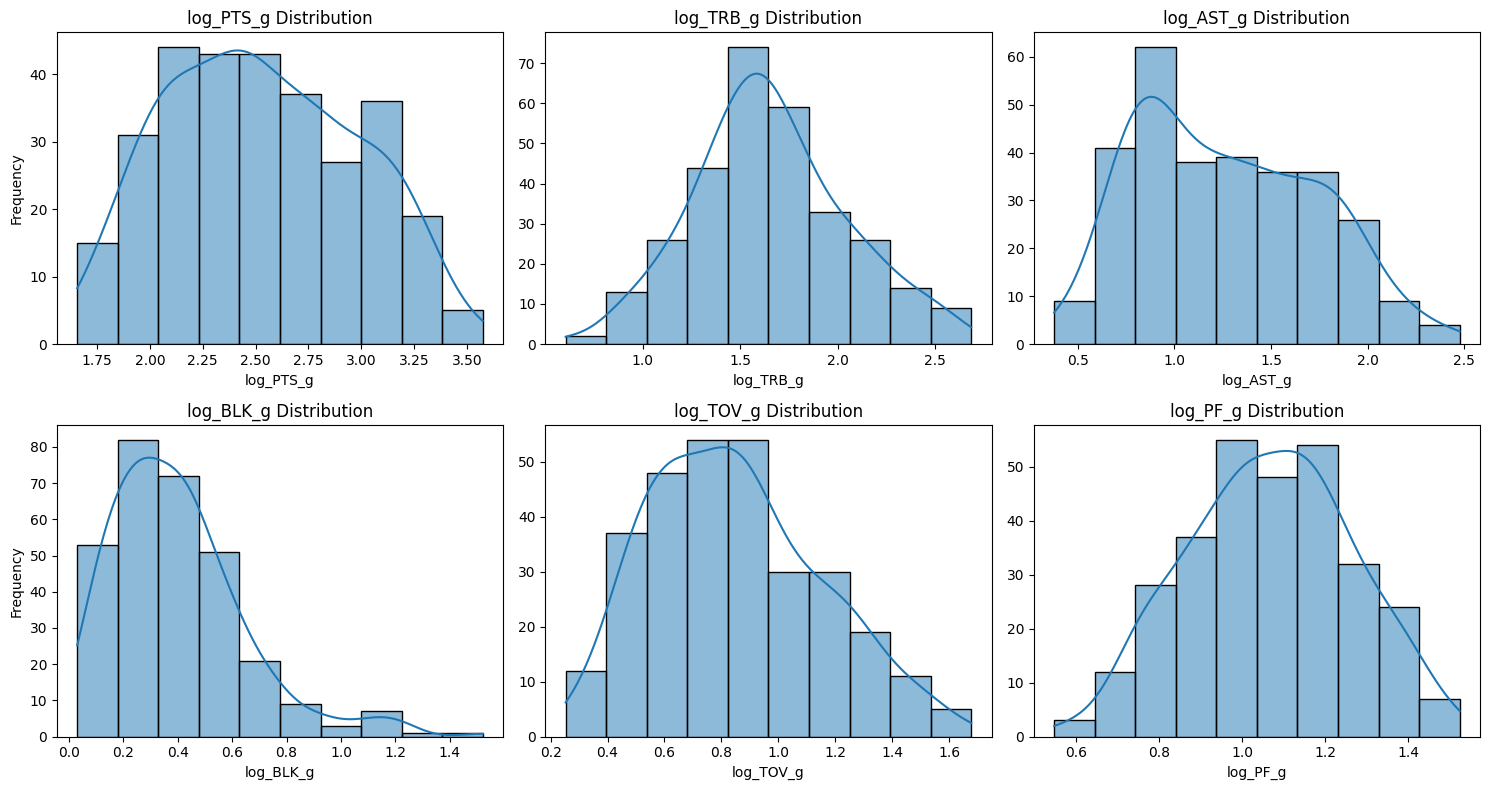

In [24]:
df = nba_data_regression_test_df_head_300.copy()

dependent_variable = 'PER'
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

# log transformation to independent variables

for col in independent_variables:
    df[f'log_{col}'] = np.log1p(df[col])


# Distribution visualize
log_independent_columns = [f'log_{col}' for col in independent_variables]

plt.figure(figsize=(15, 8)) 


num_cols_to_plot = len(log_independent_columns)
rows = (num_cols_to_plot + 2) // 3
cols = 3 

for i, col in enumerate(log_independent_columns):
    plt.subplot(rows, cols, i + 1)
    sns.histplot(df[col], kde=True, bins=10)
    plt.title(f'{col} Distribution')
    plt.xlabel(col)
    plt.ylabel('Frequency' if i % cols == 0 else '') 

plt.tight_layout()
plt.show()


In [25]:
log_columns = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g', 'log_PF_g']
df_log = df[log_columns]
df_log['PER'] = df['PER']

C:\Users\hansh\AppData\Local\Temp\ipykernel_28004\1489176562.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_log['PER'] = df['PER']


In [26]:
dependent_variable = 'PER'
df_log[f'log_{dependent_variable}'] = np.log(df[dependent_variable])

C:\Users\hansh\AppData\Local\Temp\ipykernel_28004\701345026.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_log[f'log_{dependent_variable}'] = np.log(df[dependent_variable])


In [27]:
y_log_non = df_log['PER']
X_log = df_log.drop(columns = ['PER','log_PER'])
X_log  = sm.add_constant(X_log)

model_log1 = sm.OLS(y_log_non, X_log)
results1 = model_log1.fit()
print(results1.summary())

                            OLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.649
Method:                 Least Squares   F-statistic:                     93.05
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           6.54e-65
Time:                        14:30:08   Log-Likelihood:                -704.76
No. Observations:                 300   AIC:                             1424.
Df Residuals:                     293   BIC:                             1449.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4384      1.240     -1.160      0.2

In [28]:
### log transformation regression result
y_log = df_log['log_PER']
X_log = df_log.drop(columns = ['PER', 'log_PER'])
X_log  = sm.add_constant(X_log)

model_log2 = sm.OLS(y_log, X_log)
results2 = model_log2.fit()
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     96.43
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.13e-66
Time:                        14:30:08   Log-Likelihood:                 124.52
No. Observations:                 300   AIC:                            -235.0
Df Residuals:                     293   BIC:                            -209.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5750      0.078     20.161      0.0

## Model's Residual Plot

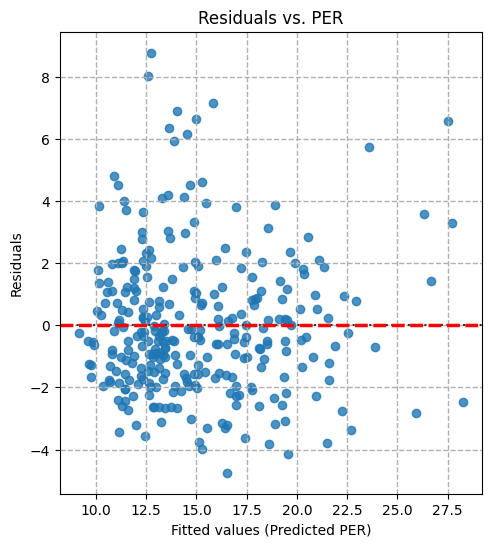

In [29]:
# original non-log transformation
plt.figure(figsize=(12, 6))

# Residuals vs Fitted plot
plt.subplot(1, 2, 1) 
sns.residplot(x=results_linear2.fittedvalues,
              y=results_linear2.resid)

plt.xlabel("Fitted values (Predicted PER)")
plt.ylabel("Residuals")
plt.title("Residuals vs. PER")
plt.grid(True, linestyle='--', alpha=1, linewidth = 1)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5)

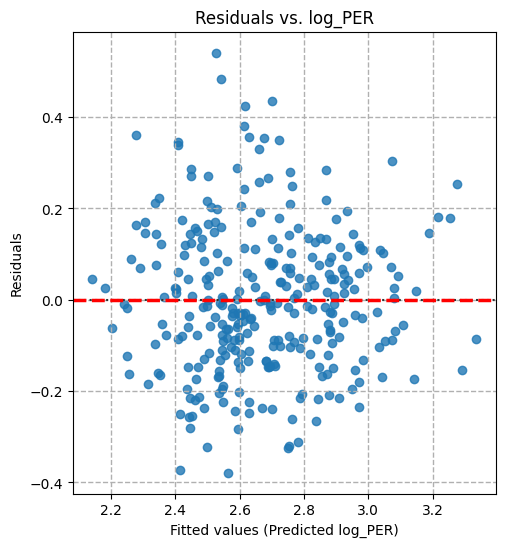

In [30]:
# log transforamtion plot

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1) 
sns.residplot(x=results2.fittedvalues,
              y=results2.resid)

plt.xlabel("Fitted values (Predicted log_PER)")
plt.ylabel("Residuals")
plt.title("Residuals vs. log_PER")
plt.grid(True, linestyle='--', alpha=1, linewidth = 1)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5) # linewidth로 두께 조절


## Correalation between V
ariables

In [31]:
nba_data_df_1_copy = nba_data_df_1.drop(columns = ['PER','FGF_g'])
nba_data_df_2_copy = nba_data_df_2.drop(columns = ['PER','STL_g','FT%'])

correlation_matrix_1 = nba_data_df_1_copy.corr()
correlation_matrix_2 = nba_data_df_2_copy.corr()

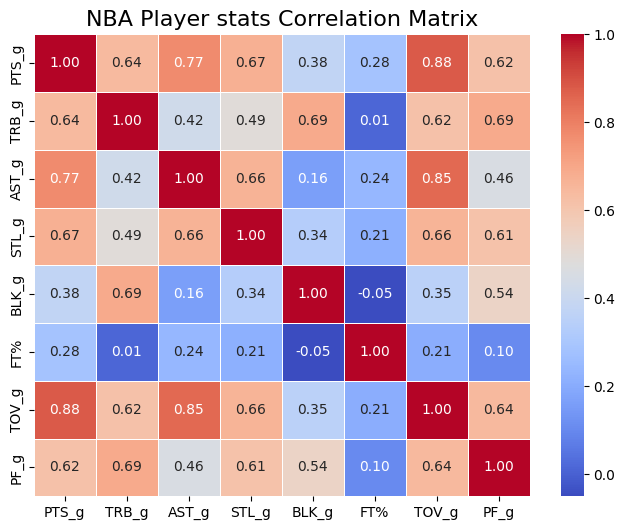

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix_1,
    annot=True,     
    cmap='coolwarm', 
    fmt=".2f",     
    linewidths=.5, 
    cbar=True 
)
plt.title('NBA Player stats Correlation Matrix', fontsize=16)

plt.show()

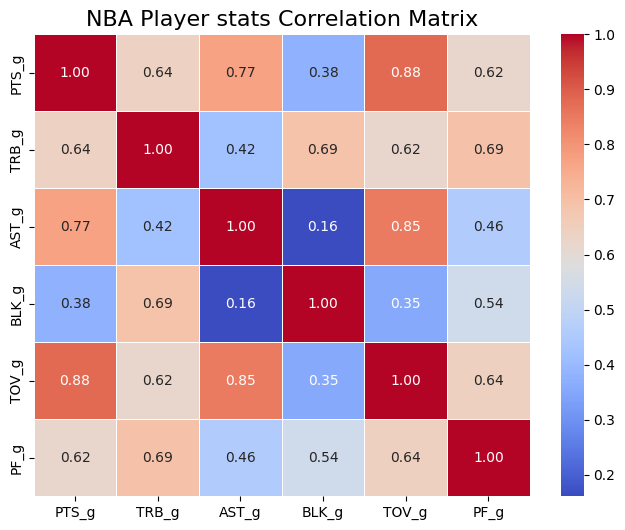

In [33]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix_2,
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f",  
    linewidths=.5, 
    cbar=True    
)

plt.title('NBA Player stats Correlation Matrix', fontsize=16)

plt.show()

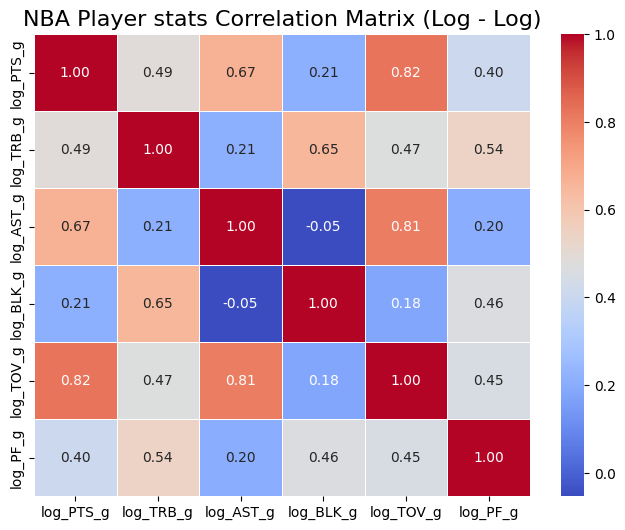

In [34]:
# Log transformation Correlation Matrix
df_log_copy = df_log.drop(columns = ['log_PER','PER'])
correlation_matrix_log = df_log_copy.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix_log,
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=.5,
    cbar=True    
)

plt.title('NBA Player stats Correlation Matrix (Log - Log)', fontsize=16)

plt.show()

## Regression Variable's VIF

In [35]:
def calculate_vif(dataframe):

    df_for_vif = dataframe.copy()

    X = add_constant(df_for_vif)

    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    vif_data = vif_data[vif_data['feature'] != 'const']

    return vif_data.sort_values(by="VIF", ascending=False)

In [36]:
print("--- regression_model_1 VIF ---")
vif_result_1 = calculate_vif(nba_data_df_1_copy)
print(vif_result_1)

print("\n--- regression_model_2 VIF ---")
vif_result_2 = calculate_vif(nba_data_df_2_copy)
print(vif_result_2)

print("\n--- log-log_model VIF ---")
vif_result_3 = calculate_vif(df_log_copy)
print(vif_result_3)

--- regression_model_1 VIF ---
  feature       VIF
7   TOV_g  7.607359
1   PTS_g  5.421382
3   AST_g  4.628148
2   TRB_g  3.270062
8    PF_g  2.649538
4   STL_g  2.384642
5   BLK_g  2.081768
6     FT%  1.162411

--- regression_model_2 VIF ---
  feature       VIF
5   TOV_g  7.469262
1   PTS_g  4.919331
3   AST_g  4.094047
2   TRB_g  3.192394
6    PF_g  2.344029
4   BLK_g  2.060823

--- log-log_model VIF ---
     feature       VIF
5  log_TOV_g  5.857169
3  log_AST_g  3.399017
1  log_PTS_g  3.261459
2  log_TRB_g  2.468600
4  log_BLK_g  1.955584
6   log_PF_g  1.653672


## Log - Log + Dummy variables

In [37]:
df_log_pos = df_log.drop(columns = ['PER'])
df_log_pos['Pos_x'] = Merged_df['Pos_x']

In [38]:
df_log_pos.head()

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER,Pos_x
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,3.335770,PG
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,3.377588,PG
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,3.397858,PF
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,3.152736,PG
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,3.433987,C


In [39]:
df_log_dummy = pd.get_dummies(df_log_pos, columns=['Pos_x'], drop_first=True, dtype=int)

In [40]:
df_log_dummy.head(5)

,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER,Pos_x_PF,Pos_x_PG,Pos_x_SF,Pos_x_SG
0,3.551258,2.326581,2.379546,0.433636,1.615136,1.140576,3.335770,0,1,0,0
1,3.435706,1.876917,1.974081,0.638339,1.150572,1.239340,3.377588,0,1,0,0
2,3.448029,2.527371,2.017639,0.733421,1.487193,1.354987,3.397858,1,0,0,0
3,3.392065,1.528312,2.046435,0.156004,1.228349,1.054357,3.152736,0,1,0,0
4,3.310266,2.591848,2.298780,0.620985,1.386294,1.240024,3.433987,0,0,0,0


In [41]:
y_log_dummy = df_log_dummy['log_PER']

X_log_dummy = df_log_dummy.drop(['log_PER'], axis = 1)

X_log_dummy = sm.add_constant(X_log_dummy)

model_log_dummy = sm.OLS(y_log_dummy, X_log_dummy)
results_model_log_dummy = model_log_dummy.fit()

print(results_model_log_dummy.summary())

                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     83.55
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           3.27e-79
Time:                        14:30:10   Log-Likelihood:                 164.80
No. Observations:                 300   AIC:                            -307.6
Df Residuals:                     289   BIC:                            -266.9
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7800      0.080     22.250      0.0

## Variance function estimate, Heteroskedasticity test

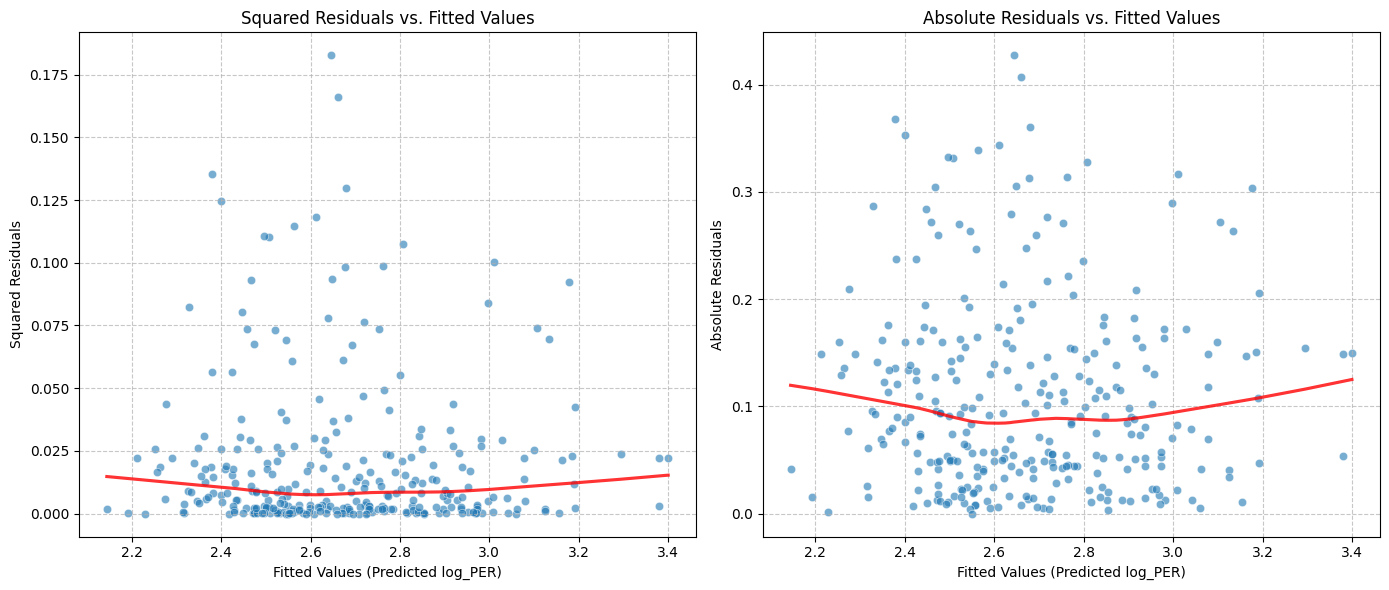

In [42]:
squared_residuals = results_model_log_dummy.resid**2
abs_residuals = np.abs(results_model_log_dummy.resid)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x=results_model_log_dummy.fittedvalues, y=squared_residuals, alpha=0.6)

sns.regplot(x=results_model_log_dummy.fittedvalues, y=squared_residuals,
            scatter=False, lowess=True, color='red', line_kws={'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted log_PER)")
plt.ylabel("Squared Residuals")
plt.title("Squared Residuals vs. Fitted Values")
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
sns.scatterplot(x=results_model_log_dummy.fittedvalues, y=abs_residuals, alpha=0.6)
sns.regplot(x=results_model_log_dummy.fittedvalues, y=abs_residuals,
            scatter=False, lowess=True, color='red', line_kws={'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted log_PER)")
plt.ylabel("Absolute Residuals")
plt.title("Absolute Residuals vs. Fitted Values")
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [43]:

from statsmodels.stats.api import het_breuschpagan, het_white

independent_vars_for_model = [
    'const', 
    'log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g',
    'log_TOV_g', 'log_PF_g',
]

results_test = model_log2.fit()

print("--- OLS Regression Results for Heteroscedasticity Test ---")
print(results_test.summary())


residuals = results_test.resid
exog_vars = results_test.model.exog 

print("\n--- Breusch-Pagan Test for Heteroscedasticity ---")

bp_test = het_breuschpagan(residuals, exog_vars)
print(f"LM Statistic: {bp_test[0]:.4f}")
print(f"LM p-value: {bp_test[1]:.4f}")
print(f"F-Statistic: {bp_test[2]:.4f}")
print(f"F p-value: {bp_test[3]:.4f}")

if bp_test[1] < 0.05: 
    print("결과: p-value가 0.05보다 작으므로 귀무가설(등분산성)을 기각합니다.")
    print("      즉, 이분산성이 존재할 가능성이 높습니다.")
else:
    print("결과: p-value가 0.05보다 크므로 귀무가설(등분산성)을 기각할 수 없습니다.")
    print("      즉, 등분산성이 존재한다고 볼 수 있습니다.")

print("\n--- White Test for Heteroscedasticity ---")
white_test = het_white(residuals, exog_vars)
print(f"LM Statistic: {white_test[0]:.4f}")
print(f"LM p-value: {white_test[1]:.4f}")
print(f"F-Statistic: {white_test[2]:.4f}")
print(f"F p-value: {white_test[3]:.4f}")

if white_test[1] < 0.05:
    print("결과: p-value가 0.05보다 작으므로 귀무가설(등분산성)을 기각합니다.")
    print("      즉, 이분산성이 존재할 가능성이 높습니다.")
else:
    print("결과: p-value가 0.05보다 크므로 귀무가설(등분산성)을 기각할 수 없습니다.")
    print("      즉, 등분산성이 존재한다고 볼 수 있습니다.")

--- OLS Regression Results for Heteroscedasticity Test ---
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.657
Method:                 Least Squares   F-statistic:                     96.43
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.13e-66
Time:                        14:30:11   Log-Likelihood:                 124.52
No. Observations:                 300   AIC:                            -235.0
Df Residuals:                     293   BIC:                            -209.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [44]:
y_log_dummy = df_log_dummy['log_PER']

X_log_dummy = df_log_dummy.drop(['log_PER'], axis = 1)

X_log_dummy = sm.add_constant(X_log_dummy)

model_log_dummy = sm.OLS(y_log_dummy, X_log_dummy)
results_ols = model_log_dummy.fit()

print("--- Initial OLS Regression Results (for comparison) ---")
print(results_ols.summary())


abs_residuals = np.abs(results_ols.resid)
fitted_values = results_ols.fittedvalues


fitted_values_with_const = sm.add_constant(fitted_values)
aux_model = sm.OLS(abs_residuals, fitted_values_with_const)
aux_results = aux_model.fit()


epsilon = 1e-6
weights_wls = 1 / (np.abs(results_ols.resid) + epsilon)


model_wls = sm.WLS(y_log_dummy, X_log_dummy, weights=weights_wls)
results_wls = model_wls.fit()

print("\n--- WLS Regression Results (after addressing Heteroscedasticity) ---")
print(results_wls.summary())


--- Initial OLS Regression Results (for comparison) ---
                            OLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     83.55
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           3.27e-79
Time:                        14:30:11   Log-Likelihood:                 164.80
No. Observations:                 300   AIC:                            -307.6
Df Residuals:                     289   BIC:                            -266.9
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

In [45]:
print(results_wls.summary())

                            WLS Regression Results                            
Dep. Variable:                log_PER   R-squared:                       0.945
Model:                            WLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     492.8
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          4.25e-175
Time:                        14:30:11   Log-Likelihood:                 309.59
No. Observations:                 300   AIC:                            -597.2
Df Residuals:                     289   BIC:                            -556.4
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7819      0.031     56.886      0.0

## Robust Standard Errors

In [46]:
columns_need2 = ['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PER', 'Pos_x']
Merged_df_predict = Merged_df_predict[columns_need2]
Merged_df_predict = Merged_df_predict.dropna()
Merged_df_predict = Merged_df_predict[Merged_df_predict['G_x'] != 0]

NameError: name 'Merged_df_predict' is not defined

In [ ]:
Merged_df_predict.columns

Index(['Player', 'G_x', 'PTS', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PER',
       'Pos_x'],
      dtype='object')

In [ ]:
nba_data_df_predict = pd.DataFrame(columns = columns_original_need)
nba_data_df_predict = nba_data_df_predict.drop(columns = ['STL_g', 'FT%', 'FGF_g'])
nba_data_df_predict.columns

Index(['Player', 'PER', 'PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g',
       'Pos_x'],
      dtype='object')

In [ ]:
nba_data_df_predict['Player'] = Merged_df_predict['Player']
nba_data_df_predict['Pos_x'] = Merged_df_predict['Pos_x']
nba_data_df_predict['PER'] = Merged_df_predict['PER']
nba_data_df_predict['PTS_g'] = Merged_df_predict['PTS'] / Merged_df_predict['G_x']
nba_data_df_predict['TRB_g'] = Merged_df_predict['TRB'] / Merged_df_predict['G_x']
nba_data_df_predict['AST_g'] = Merged_df_predict['AST'] / Merged_df_predict['G_x']
nba_data_df_predict['BLK_g'] = Merged_df_predict['BLK'] / Merged_df_predict['G_x']
nba_data_df_predict['TOV_g'] = Merged_df_predict['TOV'] / Merged_df_predict['G_x']
nba_data_df_predict['PF_g'] = Merged_df_predict['PF'] / Merged_df_predict['G_x']
nba_data_df_predict = nba_data_df_predict.head(300)
nba_data_df_predict

,Player,PER,PTS_g,TRB_g,AST_g,BLK_g,TOV_g,PF_g,Pos_x
0,Shai Gilgeous-Alexander,30.7,32.684211,4.986842,6.394737,1.013158,2.407895,2.157895,PG
1,Anthony Edwards,20.1,27.556962,5.696203,4.544304,0.645570,3.151899,1.898734,SG
2,Nikola Jokić,32.0,29.585714,12.742857,10.228571,0.642857,3.285714,2.285714,C
3,Giannis Antetokounmpo,30.5,30.388060,11.910448,6.462687,1.164179,3.074627,2.313433,PF
4,Jayson Tatum,21.7,26.833333,8.652778,5.986111,0.527778,2.902778,2.180556,PF
...,...,...,...,...,...,...,...,...,...
295,Isaac Okoro,10.7,6.127273,2.363636,1.236364,0.290909,0.418182,1.890909,SG
296,Svi Mykhailiuk,9.8,8.789474,2.368421,2.000000,0.184211,1.368421,1.131579,SF
297,Mason Plumlee,14.8,4.500000,6.148649,1.810811,0.635135,0.797297,2.081081,C
298,Ben Sheppard,9.2,5.269841,2.809524,1.349206,0.222222,0.349206,1.984127,SG


In [ ]:
df_20242025 = nba_data_df_predict.copy()

dependent_variable = 'PER'
independent_variables = ['PTS_g', 'TRB_g', 'AST_g', 'BLK_g', 'TOV_g', 'PF_g']

for col in independent_variables:
    df_20242025[f'log_{col}'] = np.log1p(df_20242025[col])
    print(f"  - '{col}' 변환 완료 -> 'log_{col}' 생성")

df_20242025[f'log_{dependent_variable}'] = np.log(df_20242025[dependent_variable])
print(f"'{dependent_variable}' 컬럼에 log(x) 변환 완료 -> 'log_{dependent_variable}' 생성")

print("\n로그 변환 후 DataFrame의 상위 5행:")
df_20242025.head(5)

  - 'PTS_g' 변환 완료 -> 'log_PTS_g' 생성
  - 'TRB_g' 변환 완료 -> 'log_TRB_g' 생성
  - 'AST_g' 변환 완료 -> 'log_AST_g' 생성
  - 'BLK_g' 변환 완료 -> 'log_BLK_g' 생성
  - 'TOV_g' 변환 완료 -> 'log_TOV_g' 생성
  - 'PF_g' 변환 완료 -> 'log_PF_g' 생성
'PER' 컬럼에 log(x) 변환 완료 -> 'log_PER' 생성

로그 변환 후 DataFrame의 상위 5행:


,Player,PER,PTS_g,TRB_g,AST_g,BLK_g,TOV_g,PF_g,Pos_x,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,log_PER
0,Shai Gilgeous-Alexander,30.7,32.684211,4.986842,6.394737,1.013158,2.407895,2.157895,PG,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906,3.424263
1,Anthony Edwards,20.1,27.556962,5.696203,4.544304,0.645570,3.151899,1.898734,SG,3.351901,1.901541,1.712771,0.498087,1.423566,1.064274,3.000720
2,Nikola Jokić,32.0,29.585714,12.742857,10.228571,0.642857,3.285714,2.285714,C,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584,3.465736
3,Giannis Antetokounmpo,30.5,30.388060,11.910448,6.462687,1.164179,3.074627,2.313433,PF,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985,3.417727
4,Jayson Tatum,21.7,26.833333,8.652778,5.986111,0.527778,2.902778,2.180556,PF,3.326234,2.267246,1.943924,0.423814,1.361689,1.157056,3.077312


In [ ]:
simple_columns = ['Player', 'Pos_x', 'PER', 'log_PER', 'log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g', 'log_TOV_g', 'log_PF_g']
nba_data_df_predict_log = df_20242025[simple_columns]
nba_data_df_predict_log.head(10)

,Player,Pos_x,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g
0,Shai Gilgeous-Alexander,PG,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906
1,Anthony Edwards,SG,20.1,3.000720,3.351901,1.901541,1.712771,0.498087,1.423566,1.064274
2,Nikola Jokić,C,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584
3,Giannis Antetokounmpo,PF,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985
4,Jayson Tatum,PF,21.7,3.077312,3.326234,2.267246,1.943924,0.423814,1.361689,1.157056
5,Devin Booker,SG,19.3,2.960105,3.282414,1.622683,2.086086,0.193371,1.369487,1.291984
6,Trae Young,PG,18.3,2.906901,3.227783,1.412270,2.532025,0.146603,1.735375,1.067429
7,Tyler Herro,SG,19.7,2.980619,3.214711,1.821612,1.872801,0.199489,1.272966,0.743791
8,Cade Cunningham,PG,20.6,3.025291,3.301114,1.956063,2.313949,0.563689,1.689041,1.331235
9,James Harden,PG,20.0,2.995732,3.170111,1.912819,2.271734,0.528392,1.670807,1.115349


In [ ]:
nba_data_df_predict_log = nba_data_df_predict_log.sort_values(by='PER', ascending=False)
nba_data_df_predict_log = nba_data_df_predict_log.head(30)
nba_data_df_predict_log.head(5)

,Player,Pos_x,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g
2,Nikola Jokić,C,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584
0,Shai Gilgeous-Alexander,PG,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906
3,Giannis Antetokounmpo,PF,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985
140,Zion Williamson,PF,27.3,3.306887,3.241289,2.104134,1.840550,0.641854,1.386294,1.317301
50,Anthony Davis,PF,26.3,3.269569,3.247482,2.531204,1.514912,1.149579,1.168041,1.072121


In [ ]:
nba_data_df_predict_log_dummy = pd.get_dummies(nba_data_df_predict_log, columns=['Pos_x'], drop_first=True, dtype=int)
nba_data_df_predict_log_dummy.head(5)

,Player,PER,log_PER,log_PTS_g,log_TRB_g,log_AST_g,log_BLK_g,log_TOV_g,log_PF_g,Pos_x_PF,Pos_x_PG,Pos_x_SF,Pos_x_SG
2,Nikola Jokić,32.0,3.465736,3.420533,2.620519,2.418462,0.496437,1.455287,1.189584,0,0,0,0
0,Shai Gilgeous-Alexander,30.7,3.424263,3.517029,1.789564,2.000769,0.699705,1.226095,1.149906,0,1,0,0
3,Giannis Antetokounmpo,30.5,3.417727,3.446428,2.558037,2.009915,0.772041,1.404779,1.197985,1,0,0,0
140,Zion Williamson,27.3,3.306887,3.241289,2.104134,1.840550,0.641854,1.386294,1.317301,1,0,0,0
50,Anthony Davis,26.3,3.269569,3.247482,2.531204,1.514912,1.149579,1.168041,1.072121,1,0,0,0


In [ ]:
trained_model_columns = results_model_log_dummy.params.index.tolist()
trained_model_columns

['const',
 'log_PTS_g',
 'log_TRB_g',
 'log_AST_g',
 'log_BLK_g',
 'log_TOV_g',
 'log_PF_g',
 'Pos_x_PF',
 'Pos_x_PG',
 'Pos_x_SF',
 'Pos_x_SG']

In [ ]:
nba_data_df_predict_log_dummy.columns

Index(['Player', 'PER', 'log_PER', 'log_PTS_g', 'log_TRB_g', 'log_AST_g',
       'log_BLK_g', 'log_TOV_g', 'log_PF_g', 'Pos_x_PF', 'Pos_x_PG',
       'Pos_x_SF', 'Pos_x_SG'],
      dtype='object')

## PER Prediction

In [ ]:
# Prediction by OLS Model
independent_vars_for_model = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g','log_TOV_g', 'log_PF_g','Pos_x_PF', 'Pos_x_PG', 'Pos_x_SF', 'Pos_x_SG']

trained_model_columns = results_model_log_dummy.params.index.tolist()
X_predict_data = nba_data_df_predict_log_dummy[independent_vars_for_model].copy() 
X_predict_data = sm.add_constant(X_predict_data, has_constant='add') 

if not all(X_predict_data.columns == trained_model_columns):
    print("경고: 예측 데이터의 컬럼 순서가 학습 모델과 다릅니다. 재정렬합니다.")
    print("학습 모델 컬럼:", trained_model_columns)
    print("예측 데이터 컬럼 (정렬 전):", X_predict_data.columns.tolist())
    X_predict_data = X_predict_data[trained_model_columns]
    print("예측 데이터 컬럼 (정렬 후):", X_predict_data.columns.tolist())

predicted_log_PER = results_model_log_dummy.predict(X_predict_data)

predicted_PER = np.exp(predicted_log_PER)

nba_data_df_predict_log_dummy['Predicted_log_PER'] = predicted_log_PER
nba_data_df_predict_log_dummy['Predicted_PER'] = predicted_PER

comparison_df = nba_data_df_predict_log_dummy[['Player', 'PER', 'Predicted_PER']]
comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100

mean_abs_error = comparison_df['Absolute_Error_PER'].mean()
mean_perc_error = comparison_df['Percentage_Error_PER'].mean()
print(f"\n평균 절대 오차 (PER): {mean_abs_error:.2f}")
print(f"평균 백분율 오차 (PER): {mean_perc_error:.2f}%")
comparison_df


평균 절대 오차 (PER): 2.83
평균 백분율 오차 (PER): 11.83%


C:\Users\hansh\AppData\Local\Temp\ipykernel_32456\1062976819.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
C:\Users\hansh\AppData\Local\Temp\ipykernel_32456\1062976819.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100


,Player,PER,Predicted_PER,Absolute_Error_PER,Percentage_Error_PER
2,Nikola Jokić,32.0,30.648757,1.351243,4.222633
0,Shai Gilgeous-Alexander,30.7,23.042240,7.657760,24.943845
3,Giannis Antetokounmpo,30.5,24.618001,5.881999,19.285242
140,Zion Williamson,27.3,19.325668,7.974332,29.210008
50,Anthony Davis,26.3,24.367833,1.932167,7.346642
153,Daniel Gafford,24.7,19.530277,5.169723,20.930053
70,Victor Wembanyama,24.2,28.796435,4.596435,18.993535
32,Luka Dončić,24.1,20.900682,3.199318,13.275180
168,Mark Williams,23.9,22.552812,1.347188,5.636771
10,Karl-Anthony Towns,23.4,23.579302,0.179302,0.766250


In [ ]:
# Prediction by OLS Model
model_wls = sm.WLS(y_log_dummy, X_log_dummy, weights=weights_wls)
results_wls = model_wls.fit()

independent_vars_for_model = ['log_PTS_g', 'log_TRB_g', 'log_AST_g', 'log_BLK_g','log_TOV_g', 'log_PF_g','Pos_x_PF', 'Pos_x_PG', 'Pos_x_SF', 'Pos_x_SG']

trained_model_columns = results_wls.params.index.tolist()

X_predict_data = nba_data_df_predict_log_dummy[independent_vars_for_model].copy() 

X_predict_data = sm.add_constant(X_predict_data, has_constant='add') 

if not all(X_predict_data.columns == trained_model_columns):
    print("경고: 예측 데이터의 컬럼 순서가 학습 모델과 다릅니다. 재정렬합니다.")
    print("학습 모델 컬럼:", trained_model_columns)
    print("예측 데이터 컬럼 (정렬 전):", X_predict_data.columns.tolist())
    X_predict_data = X_predict_data[trained_model_columns]
    print("예측 데이터 컬럼 (정렬 후):", X_predict_data.columns.tolist())

predicted_log_PER = results_wls.predict(X_predict_data)

predicted_PER = np.exp(predicted_log_PER)

nba_data_df_predict_log_dummy['Predicted_log_PER'] = predicted_log_PER
nba_data_df_predict_log_dummy['Predicted_PER'] = predicted_PER

comparison_df = nba_data_df_predict_log_dummy[['Player', 'PER', 'Predicted_PER']]
comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100

mean_abs_error = comparison_df['Absolute_Error_PER'].mean()
mean_perc_error = comparison_df['Percentage_Error_PER'].mean()
print(f"\n평균 절대 오차 (PER): {mean_abs_error:.2f}")
print(f"평균 백분율 오차 (PER): {mean_perc_error:.2f}%")
comparison_df


평균 절대 오차 (PER): 2.87
평균 백분율 오차 (PER): 11.99%


C:\Users\hansh\AppData\Local\Temp\ipykernel_32456\3457839095.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Absolute_Error_PER'] = np.abs(comparison_df['PER'] - comparison_df['Predicted_PER'])
C:\Users\hansh\AppData\Local\Temp\ipykernel_32456\3457839095.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  comparison_df['Percentage_Error_PER'] = (comparison_df['Absolute_Error_PER'] / comparison_df['PER']) * 100


,Player,PER,Predicted_PER,Absolute_Error_PER,Percentage_Error_PER
2,Nikola Jokić,32.0,30.651975,1.348025,4.212577
0,Shai Gilgeous-Alexander,30.7,22.853159,7.846841,25.559744
3,Giannis Antetokounmpo,30.5,24.412082,6.087918,19.960388
140,Zion Williamson,27.3,19.305624,7.994376,29.283428
50,Anthony Davis,26.3,23.965172,2.334828,8.877671
153,Daniel Gafford,24.7,19.424432,5.275568,21.358573
70,Victor Wembanyama,24.2,28.321135,4.121135,17.029482
32,Luka Dončić,24.1,20.697815,3.402185,14.116950
168,Mark Williams,23.9,22.393265,1.506735,6.304330
10,Karl-Anthony Towns,23.4,23.512454,0.112454,0.480575


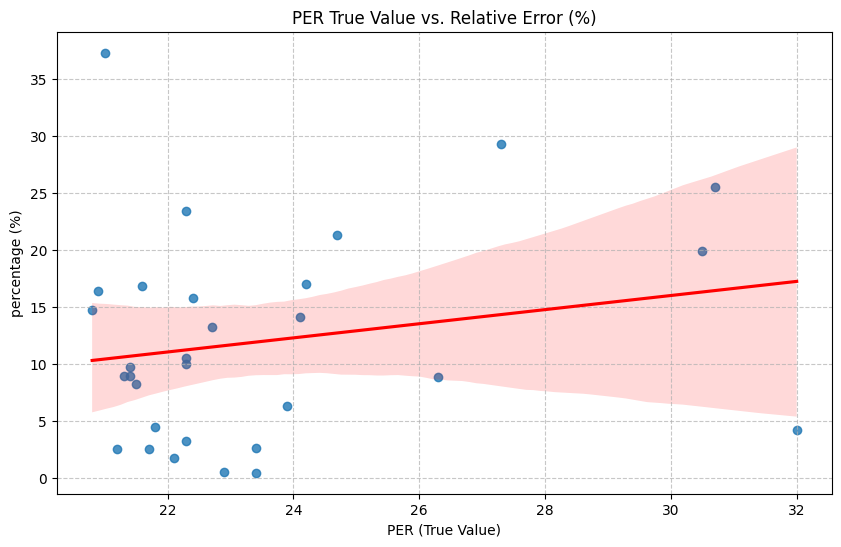

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(x='PER', y='Percentage_Error_PER', data=comparison_df, scatter_kws={'alpha':0.8}, line_kws={'color': 'red'})

plt.title('PER True Value vs. Relative Error (%)')
plt.xlabel('PER (True Value)')
plt.ylabel('percentage (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()